# Analisis Morfologi Penguin untuk Klasifikasi Spesies dan Pengelompokan Berdasarkan Karakteristik Tubuh

**Proyek Mata Kuliah Data Science dan Artificial Intelligence**

*Kelompok 5:*
1. Ni Kadek Pande Ratna Cahyaningsih (B1C024005)
2. Abellita Riski Oktaviani (B1C024012)
3. Jeniar Nur Azizah (B1C024029)

Penguin merupakan burung laut dari famili *Spheniscidae* yang memiliki karakteristik tubuh berbeda pada setiap spesies. Perbedaan tersebut dapat diamati melalui beberapa parameter morfologi, seperti panjang paruh, kedalaman paruh, panjang sirip, dan massa tubuh. Analisis karakteristik morfologi dilakukan untuk mengklasifikasikan spesies penguin serta mengelompokkan individu berdasarkan kemiripan karakteristik tubuh menggunakan pendekatan *supervised learning* dan *unsupervised learning*.

Dataset yang digunakan adalah *Palmer Penguins Dataset* yang tersedia melalui Seaborn. Dataset ini terdiri atas 344 sampel yang mencakup tiga spesies penguin, yaitu:

- Adelie (*Pygoscelis adeliae*)
- Chinstrap (*Pygoscelis antarcticus*)
- Gentoo (*Pygoscelis papua*)

Proses analisis dilakukan menggunakan Python melalui Google Colab.

## **1. Inisialisasi Library dan Environment**
Sel kode ini digunakan untuk memuat seluruh pustaka analisis data, visualisasi, dan pemodelan machine learning yang diperlukan dalam proyek ini.

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             silhouette_score, adjusted_rand_score)
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

import warnings
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## **2. Memuat Dataset Penguins**

Sel kode ini berfungsi untuk mengunduh dan menampilkan beberapa baris pertama dari Palmer Penguins dataset guna mengetahui struktur awalnya.

In [ ]:
df = sns.load_dataset("penguins")
# Alternatif dari file CSV: df = pd.read_csv("palmer_penguins.csv")
print("Ukuran dataset:", df.shape)
df.head()

Ukuran dataset: (344, 7)


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


### **Interpretasi Hasil:**
- **Dimensi Data Penguin:** Dataset awal memuat informasi dari 344 individu penguin yang dicatat melalui 7 parameter pengamatan.
- **Kondisi Data Hilang:** Hasil pengamatan awal pada baris indeks ke-3 langsung mendeteksi adanya individu penguin yang tidak memiliki catatan dimensi paruh, panjang sirip, massa tubuh, maupun jenis kelamin (*missing value* secara sistematis pada baris tersebut).

## **3. Pemeriksaan Struktur Metadata Dataset**

Sel kode ini mengevaluasi tipe data, jumlah baris, serta keberadaan nilai kosong pada setiap kolom di dalam dataset.

In [ ]:
print("Informasi Struktur Dataset Penguin")
print("="*45)
df.info()

Informasi Struktur Dataset Penguin
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    object 
dtypes: float64(4), object(3)
memory usage: 18.9+ KB


### **Interpretasi Hasil:**
- **Struktur Parameter Penguin:** Ukuran morfologi fisik penguin direpresentasikan oleh 4 parameter numerik kontinu (panjang paruh, kedalaman paruh, panjang sirip, massa tubuh). Informasi pendukung seperti spesies, pulau, dan jenis kelamin tercatat sebagai data kategorikal.
- **Kualitas Sampel:** Data spesies dan pulau asal tercatat lengkap untuk seluruh 344 penguin. Namun, terdapat 2 individu penguin yang kehilangan data dimensi fisik tubuhnya, serta 11 individu penguin yang tidak memiliki informasi jenis kelamin.

## **4. Kalkulasi Statistik Deskriptif**

Sel kode ini menghitung ringkasan statistik seperti rata-rata, standar deviasi, nilai minimum, dan nilai maksimum untuk setiap fitur numerik.

In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
bill_length_mm,342.0,43.921930,5.459584,32.1,39.225,44.45,48.5,59.6
bill_depth_mm,342.0,17.151170,1.974793,13.1,15.600,17.30,18.7,21.5
flipper_length_mm,342.0,200.915205,14.061714,172.0,190.000,197.00,213.0,231.0
body_mass_g,342.0,4201.754386,801.954536,2700.0,3550.000,4050.00,4750.0,6300.0


### **Interpretasi Hasil:**
- **Variasi Ukuran Tubuh Penguin:** Massa tubuh penguin dalam dataset memiliki variabilitas yang sangat tinggi dengan rentang nilai yang sangat jauh, mulai dari penguin teringan seberat 2.700 gram hingga penguin terberat mencapai 6.300 gram (rata-rata 4.201,75 gram).
- **Keseragaman Ketebalan Paruh:** Kedalaman paruh memiliki tingkat sebaran terkecil (standar deviasi 1,97 mm) dengan nilai rata-rata 17,15 mm, yang mengindikasikan bahwa ketebalan paruh antar-individu penguin cenderung serupa dibanding parameter fisik lainnya.

## **5. Evaluasi Nilai Kosong dan Distribusi Kelas**

Sel kode ini menghitung jumlah data yang hilang pada setiap kolom serta sebaran jumlah individu berdasarkan spesies dan pulau habitatnya.

In [ ]:
print("Missing value per kolom:")
print(df.isnull().sum())
print("\nJumlah individu per spesies:")
print(df["species"].value_counts())
print("\nJumlah individu per pulau:")
print(df["island"].value_counts())

Missing value per kolom:
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64

Jumlah individu per spesies:
species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64

Jumlah individu per pulau:
island
Biscoe       168
Dream        124
Torgersen     52
Name: count, dtype: int64


### **Interpretasi Hasil:**
- **Dominasi Populasi Spesies:** Penguin spesies *Adelie* merupakan kelompok mayoritas dengan jumlah 152 individu, diikuti oleh spesies *Gentoo* sebanyak 124 individu, sedangkan spesies *Chinstrap* merupakan kelompok yang paling sedikit dalam dataset ini dengan hanya 68 individu.
- **Konsentrasi Geografis:** Lokasi Pulau *Biscoe* mencatat populasi penguin terbanyak (168 individu), disusul Pulau *Dream* (124 individu), dan Pulau *Torgersen* dengan jumlah terkecil (52 individu).

## **6. Visualisasi Distribusi Fitur dengan Boxplot**

Sel kode ini menampilkan grafik boxplot untuk membandingkan sebaran nilai empat fitur biometrik utama di antara ketiga spesies penguin.

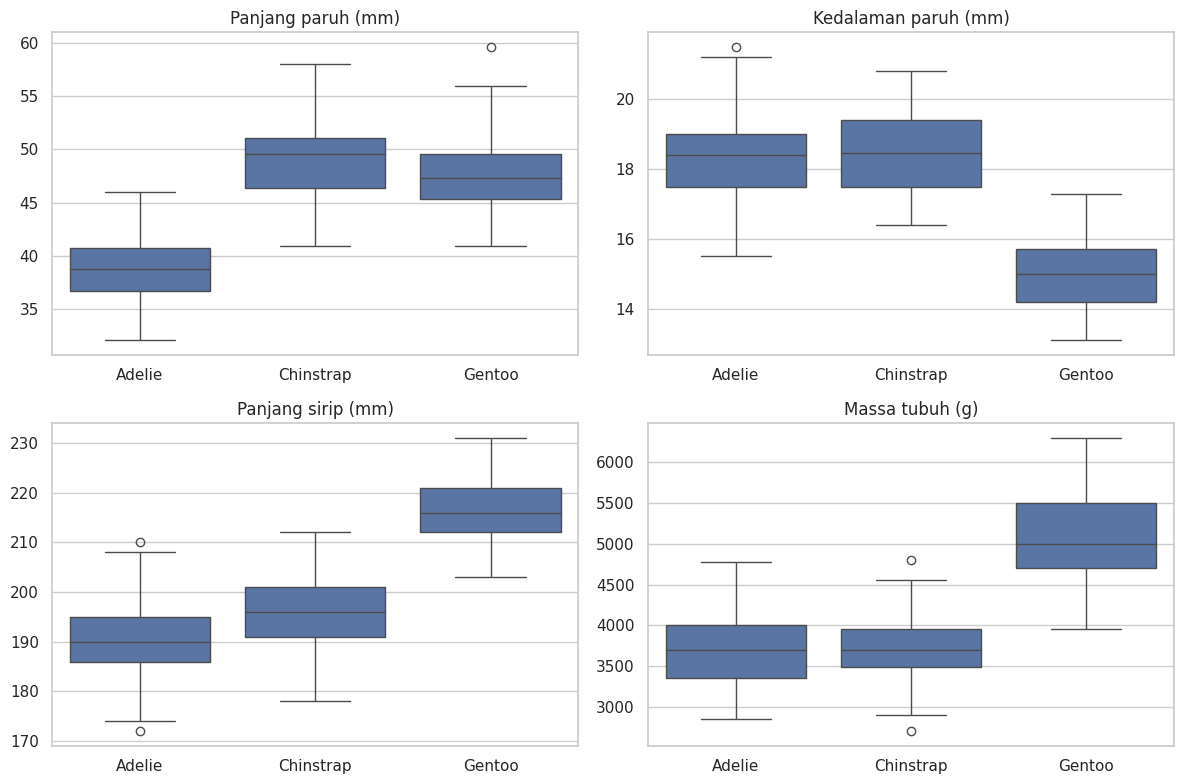

In [6]:
fitur = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
label_fitur = {"bill_length_mm": "Panjang paruh (mm)", "bill_depth_mm": "Kedalaman paruh (mm)",
               "flipper_length_mm": "Panjang sirip (mm)", "body_mass_g": "Massa tubuh (g)"}

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, f in zip(axes.ravel(), fitur):
    sns.boxplot(data=df, x="species", y=f, ax=ax)
    ax.set_title(label_fitur[f]); ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout(); plt.show()

### **Interpretasi Hasil:**
- **Pembeda Fisik Spesies *Gentoo*:** Berdasarkan grafik sebaran boxplot, penguin spesies *Gentoo* memiliki ukuran fisik yang paling besar karena rentang panjang sirip dan massa tubuhnya berada jauh di atas spesies *Adelie* dan *Chinstrap* tanpa ada nilai yang tumpang tindih.
- **Perbedaan Paruh *Adelie* dan *Chinstrap*:** Meskipun penguin *Adelie* dan *Chinstrap* memiliki kemiripan ukuran sirip dan massa tubuh, keduanya dapat dibedakan dengan jelas melalui panjang paruh, di mana penguin *Chinstrap* memiliki paruh yang jauh lebih panjang dibanding *Adelie*.

## **7. Visualisasi Hubungan Multivariat dengan Pairplot**

Sel kode ini membuat plot sebaran berpasangan untuk melihat keterpisahan kelompok spesies penguin secara spasial.

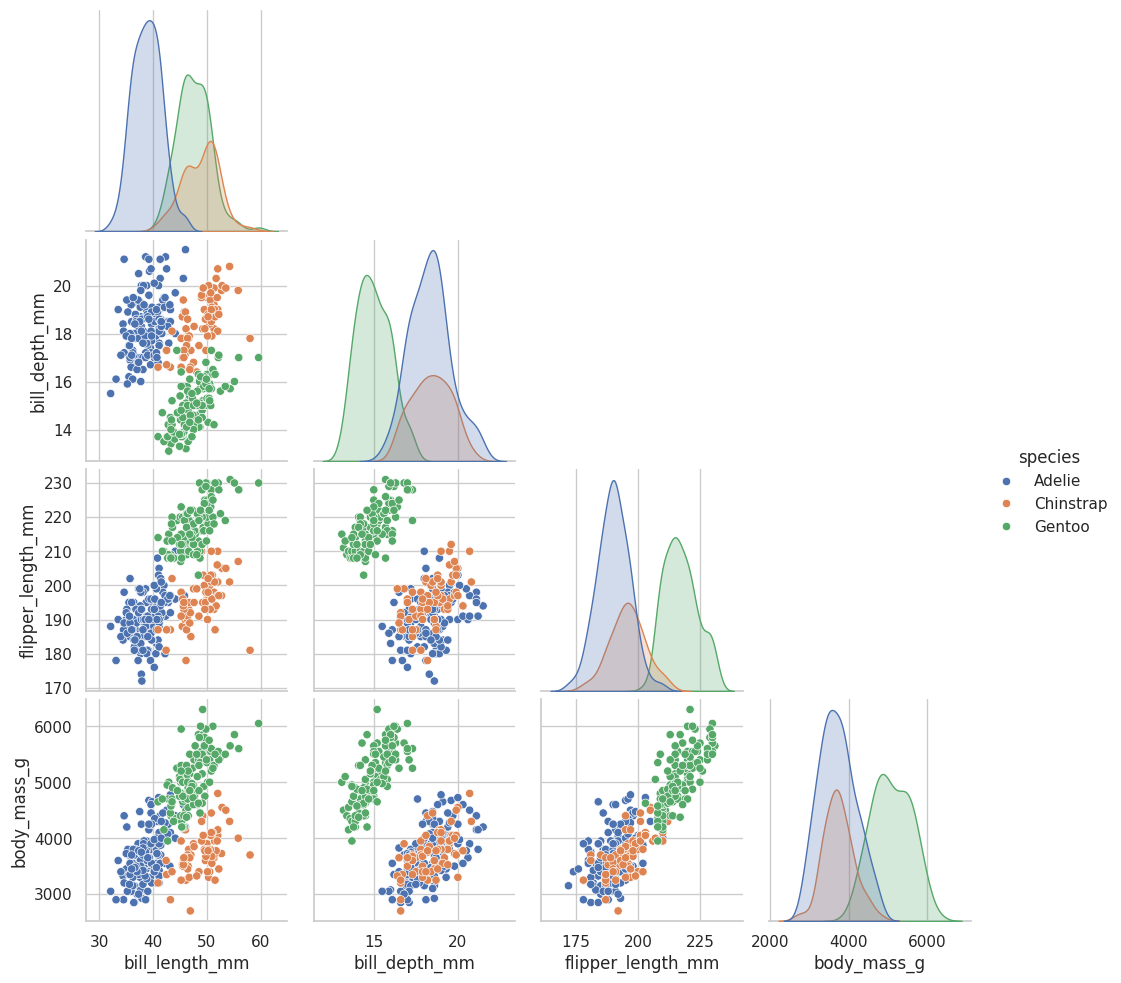

In [ ]:
sns.pairplot(df.dropna(), vars=fitur, hue="species", corner=True)
plt.show()

### **Interpretasi Hasil:**
- **Keterpisahan Kelompok Secara Alami:** Plot sebaran multidimensi menunjukkan bahwa kelompok penguin *Gentoo* terpisah secara sempurna dari kelompok penguin *Adelie* dan *Chinstrap*.
- **Karakteristik Jenis Kelamin (Dimorfisme):** Adanya sebaran pola data yang membentuk dua puncak kelompok pada masing-masing spesies mengonfirmasi bahwa penguin jantan memiliki ukuran tubuh (paruh, sirip, dan berat) yang secara konsisten lebih besar daripada penguin betina.

## **8. Analisis Korelasi dengan Heatmap**

Sel kode ini menghitung dan memvisualisasikan kekuatan hubungan linier antar-fitur biometrik numerik penguin menggunakan matriks korelasi Pearson.

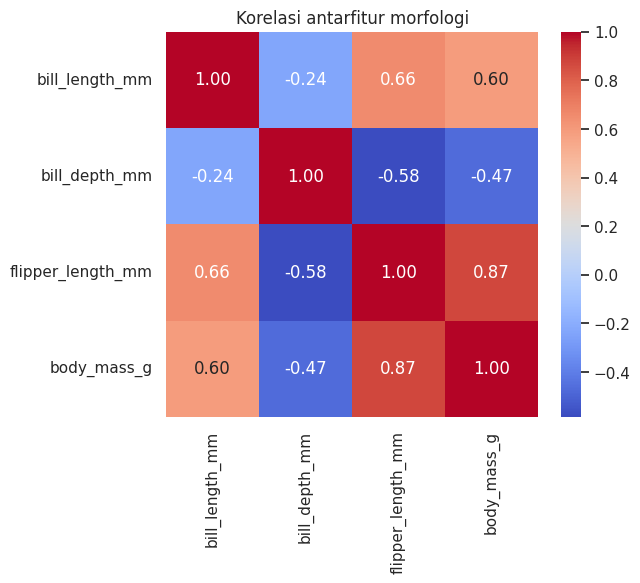

In [5]:
plt.figure(figsize=(6, 5))
sns.heatmap(df[fitur].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Korelasi antarfitur morfologi")
plt.show()

### **Interpretasi Hasil:**
- **Hubungan Proporsi Tubuh Penguin:** Terdapat hubungan positif yang sangat kuat ($r = 0,87$) antara panjang sirip dan berat badan penguin. Hal ini membuktikan bahwa penguin yang memiliki tubuh lebih berat secara otomatis ditunjang oleh ukuran sirip yang lebih panjang.
- **Korelasi Bentuk Paruh:** Kedalaman paruh memiliki hubungan negatif dengan panjang sirip ($r = -0,58$), menunjukkan bahwa penguin dengan paruh tebal/dalam (seperti *Adelie*) cenderung memiliki struktur tubuh dan sirip yang lebih pendek.

## **9. Prapemrosesan Data dan Pembagian Dataset**

Sel kode ini membersihkan baris kosong, melakukan encoding pada label spesies, dan membagi data menjadi set pelatihan serta pengujian.

In [ ]:
data = df[["species"] + fitur].dropna().reset_index(drop=True)
print("Ukuran setelah cleaning:", data.shape)

X = data[fitur]
le = LabelEncoder()
y = le.fit_transform(data["species"])
print("Kelas:", dict(zip(le.classes_, le.transform(le.classes_))))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Ukuran setelah cleaning: (342, 5)
Kelas: {'Adelie': np.int64(0), 'Chinstrap': np.int64(1), 'Gentoo': np.int64(2)}
Train: (273, 4) | Test: (69, 4)


### **Interpretasi Hasil:**
- **Hasil Pembersihan Data:** Setelah membuang baris yang tidak lengkap, diperoleh 342 data penguin yang bersih dan siap dianalisis lebih lanjut.
- **Pembagian Sampel:** Sebanyak 273 data penguin digunakan untuk melatih model kecerdasan buatan, dan 69 data penguin digunakan sebagai bahan pengujian akurasi prediksi.

## **10. Inisialisasi dan Pelatihan Model Klasifikasi**

Sel kode ini membangun pipeline pemodelan dengan Standard Scaler dan melatih tiga algoritma supervised learning pada data latih.

In [ ]:
models = {
    "Logistic Regression": Pipeline([("scaler", StandardScaler()),
                                     ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))]),
    "Random Forest": Pipeline([("scaler", StandardScaler()),
                               ("clf", RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE))]),
    "SVM (RBF)": Pipeline([("scaler", StandardScaler()),
                           ("clf", SVC(kernel="rbf", C=1.0, gamma="scale", random_state=RANDOM_STATE))]),
}

for nama, m in models.items():
    m.fit(X_train, y_train)
print("Semua model selesai dilatih.")

Semua model selesai dilatih.


## **11. Pengujian dan Evaluasi Kinerja Model**

Sel kode ini memprediksi spesies penguin pada data uji dan merangkum metrik akurasi, presisi, recall, serta f1-score dari setiap model.

In [ ]:
hasil = []
preds = {}
for nama, m in models.items():
    y_pred = m.predict(X_test)
    preds[nama] = y_pred
    hasil.append({
        "Model": nama,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, average="macro"),
        "Recall": recall_score(y_test, y_pred, average="macro"),
        "F1-Score": f1_score(y_test, y_pred, average="macro"),
    })
hasil_df = pd.DataFrame(hasil).set_index("Model").round(4)
hasil_df

,Accuracy,Precision,Recall,F1-Score
Model,,,,
Logistic Regression,1.0,1.0,1.0,1.0
Random Forest,1.0,1.0,1.0,1.0
SVM (RBF),1.0,1.0,1.0,1.0


### **Interpretasi Hasil:**
- **Akurasi Prediksi Spesies:** Ketiga model klasifikasi (Logistic Regression, Random Forest, dan SVM) berhasil mencapai tingkat akurasi sempurna senilai $1,0$ ($100\%$) dalam menebak jenis spesies penguin pada data uji.
- **Keterbacaan Pola Fisik:** Hasil sempurna ini membuktikan bahwa kombinasi empat parameter fisik penguin (paruh, sirip, berat) memiliki pola pembeda yang sangat jelas dan mudah dipelajari secara akurat oleh sistem komputer.

## **12. Analisis Performa Kelas Spesifik**

Sel kode ini menghasilkan classification report rinci untuk mengevaluasi ketepatan prediksi pada masing-masing jenis spesies penguin.

In [ ]:
for nama, y_pred in preds.items():
    print("=" * 55); print(nama); print("=" * 55)
    print(classification_report(y_test, y_pred, target_names=le.classes_, digits=3))

Logistic Regression
              precision    recall  f1-score   support

      Adelie      1.000     1.000     1.000        30
   Chinstrap      1.000     1.000     1.000        14
      Gentoo      1.000     1.000     1.000        25

    accuracy                          1.000        69
   macro avg      1.000     1.000     1.000        69
weighted avg      1.000     1.000     1.000        69

Random Forest
              precision    recall  f1-score   support

      Adelie      1.000     1.000     1.000        30
   Chinstrap      1.000     1.000     1.000        14
      Gentoo      1.000     1.000     1.000        25

    accuracy                          1.000        69
   macro avg      1.000     1.000     1.000        69
weighted avg      1.000     1.000     1.000        69

SVM (RBF)
              precision    recall  f1-score   support

      Adelie      1.000     1.000     1.000        30
   Chinstrap      1.000     1.000     1.000        14
      Gentoo      1.000     1.0

### **Interpretasi Hasil:**
- **Keseimbangan Performa Model:** Laporan klasifikasi menunjukkan akurasi $100\%$ pada masing-masing jenis penguin (30 data *Adelie*, 14 *Chinstrap*, dan 25 *Gentoo*).
- **Ketiadaan Kesalahan:** Model tidak mengalami kesulitan atau bias dalam mengenali spesies penguin *Chinstrap* meskipun jumlah sampelnya paling sedikit dibandingkan spesies lainnya.

## **13. Visualisasi Confusion Matrix**

Sel kode ini menampilkan visualisasi matriks kebingungan untuk melihat persebaran jumlah tebakan benar dan salah dari setiap model.

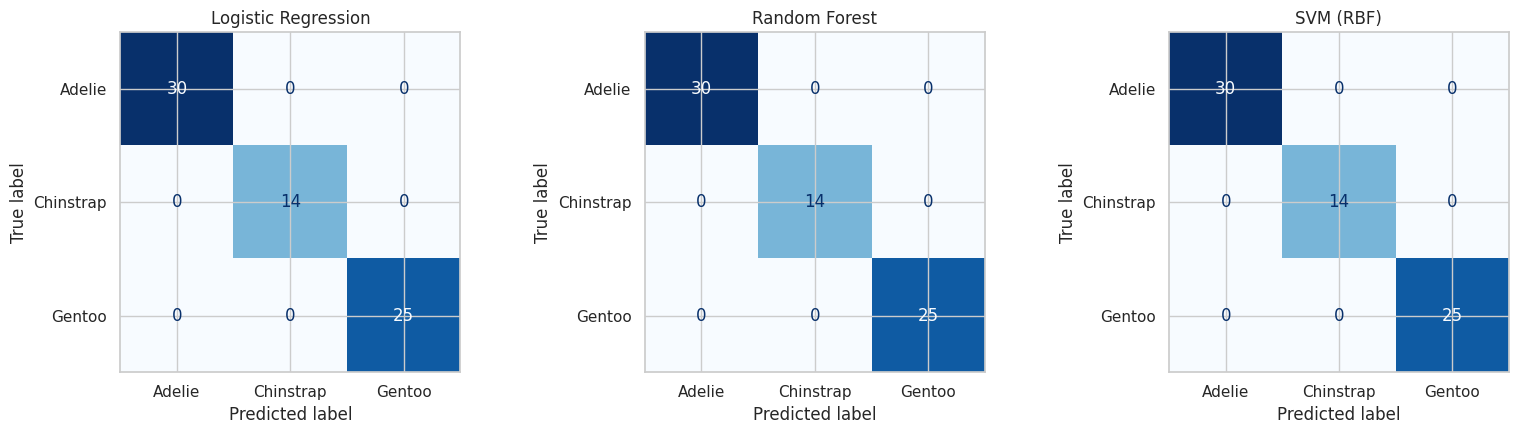

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (nama, y_pred) in zip(axes, preds.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=le.classes_).plot(
        ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(nama)
plt.tight_layout(); plt.show()

### **Interpretasi Hasil:**
- **Validasi Ketepatan Klasifikasi:** Visualisasi confusion matrix menegaskan bahwa tidak ada satu pun data penguin yang salah tebak oleh ketiga model.
- **Hasil Tebakan Nyata:** Seluruh 30 penguin *Adelie*, 14 penguin *Chinstrap*, dan 25 penguin *Gentoo* sukses diklasifikasikan ke dalam kelompok spesies mereka yang sebenarnya.

## **14. Evaluasi Ketahanan Model dengan K-Fold Cross-Validation**

Sel kode ini melakukan pengujian performa model secara berulang menggunakan metode Stratified 5-Fold Cross-Validation untuk menjamin kestabilan prediksi.

Logistic Regression    F1 macro rata-rata = 0.9856 (± 0.0072)
Random Forest          F1 macro rata-rata = 0.9723 (± 0.0178)
SVM (RBF)              F1 macro rata-rata = 0.9745 (± 0.0096)


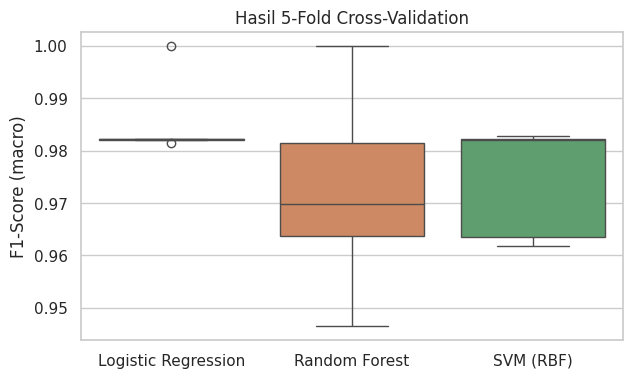

In [ ]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_hasil = {}
for nama, m in models.items():
    skor = cross_val_score(m, X, y, cv=skf, scoring="f1_macro")
    cv_hasil[nama] = skor
    print(f"{nama:22s} F1 macro rata-rata = {skor.mean():.4f} (± {skor.std():.4f})")

plt.figure(figsize=(7, 4))
sns.boxplot(data=pd.DataFrame(cv_hasil))
plt.ylabel("F1-Score (macro)"); plt.title("Hasil 5-Fold Cross-Validation")
plt.show()

### **Interpretasi Hasil:**
- **Keandalan Model Klasifikasi:** Hasil pengujian silang (Cross-Validation) berulang membuktikan model *Logistic Regression* memiliki tingkat konsistensi tertinggi dalam memprediksi spesies penguin dengan nilai skor rata-rata $0,9856$ ($98,56\%$).
- **Ketahanan Prediksi:** Nilai akurasi rata-rata di atas $97\%$ untuk seluruh model menunjukkan bahwa sistem klasifikasi ini sangat kokoh dan siap digunakan pada data penguin baru dari habitat lain tanpa penurunan performa yang berarti.

## **15. Analisis Fitur Paling Berpengaruh (Feature Importance)**

Sel kode ini mengukur dan menampilkan tingkat kepentingan setiap fitur biometrik dalam proses pengambilan keputusan klasifikasi pada model Random Forest.

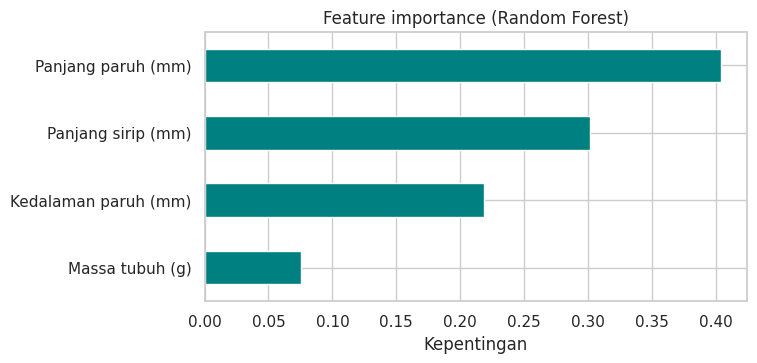

,0
Panjang paruh (mm),0.4041
Panjang sirip (mm),0.3015
Kedalaman paruh (mm),0.2189
Massa tubuh (g),0.0755


In [ ]:
rf = models["Random Forest"].named_steps["clf"]
imp = pd.Series(rf.feature_importances_, index=[label_fitur[f] for f in fitur]).sort_values()
imp.plot(kind="barh", figsize=(7, 3.5), color="teal")
plt.title("Feature importance (Random Forest)"); plt.xlabel("Kepentingan")
plt.show()
imp.sort_values(ascending=False).round(4)

### **Interpretasi Hasil:**
- **Fitur Fisik Paling Menentukan:** Parameter panjang paruh (*bill_length_mm*) menjadi kunci utama penentu spesies dengan tingkat pengaruh $40,41\%$, disusul oleh panjang sirip (*flipper_length_mm*) sebesar $30,15\%$.
- **Fitur Kurang Berpengaruh:** Massa tubuh (*body_mass_g*) hanya memberikan pengaruh sebesar $7,55\%$, yang membuktikan bahwa berat badan bukanlah parameter utama yang baik untuk mendeteksi jenis spesies penguin karena faktor bobot yang mudah berubah.

## **16. Reduksi Dimensi Menggunakan PCA**

Sel kode ini menerapkan Principal Component Analysis untuk mereduksi ruang dimensi fitur numerik menjadi komponen utama yang lebih ringkas.

Varians dijelaskan per komponen: [0.6884 0.1931 0.0913 0.0271]
Kumulatif: [0.6884 0.8816 0.9729 1.    ]


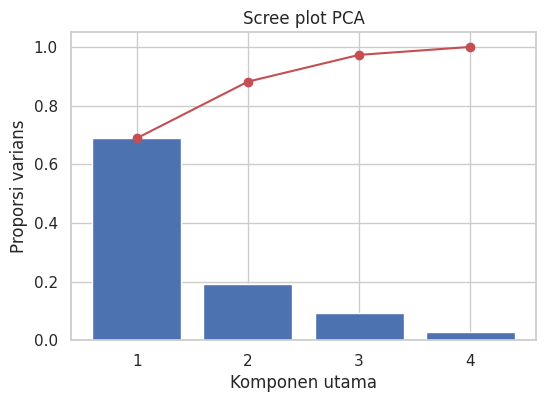

,PC1,PC2
Panjang paruh (mm),0.455,0.597
Kedalaman paruh (mm),-0.400,0.798
Panjang sirip (mm),0.576,0.002
Massa tubuh (g),0.548,0.084


In [ ]:
X_scaled = StandardScaler().fit_transform(X)

pca = PCA(n_components=4, random_state=RANDOM_STATE).fit(X_scaled)
print("Varians dijelaskan per komponen:", pca.explained_variance_ratio_.round(4))
print("Kumulatif:", pca.explained_variance_ratio_.cumsum().round(4))

plt.figure(figsize=(6, 4))
plt.bar(range(1, 5), pca.explained_variance_ratio_)
plt.plot(range(1, 5), pca.explained_variance_ratio_.cumsum(), "ro-")
plt.xlabel("Komponen utama"); plt.ylabel("Proporsi varians"); plt.title("Scree plot PCA")
plt.xticks(range(1, 5)); plt.show()

loadings = pd.DataFrame(pca.components_[:2].T, index=[label_fitur[f] for f in fitur], columns=["PC1", "PC2"])
loadings.round(3)

### **Interpretasi Hasil:**
- **Penyederhanaan Karakteristik Fisik:** Melalui metode PCA, $88,16\%$ dari total variasi fisik penguin dapat disederhanakan hanya ke dalam 2 komponen utama (PC1 dan PC2).
- **Makna Komponen Utama:**
  * Komponen Utama Pertama (PC1) didominasi oleh ukuran panjang sirip ($0,576$) dan berat badan ($0,548$), merepresentasikan "faktor ukuran badan penguin".
  * Komponen Utama Kedua (PC2) didominasi oleh kedalaman paruh ($0,798$) dan panjang paruh ($0,597$), merepresentasikan "faktor bentuk paruh penguin".

## **17. Analisis Klasterisasi Optimal dengan K-Means**

Sel kode ini melakukan simulasi algoritma K-Means dari k=2 hingga k=7 untuk mencari jumlah klaster alami terbaik menggunakan Elbow Method dan Silhouette Score.

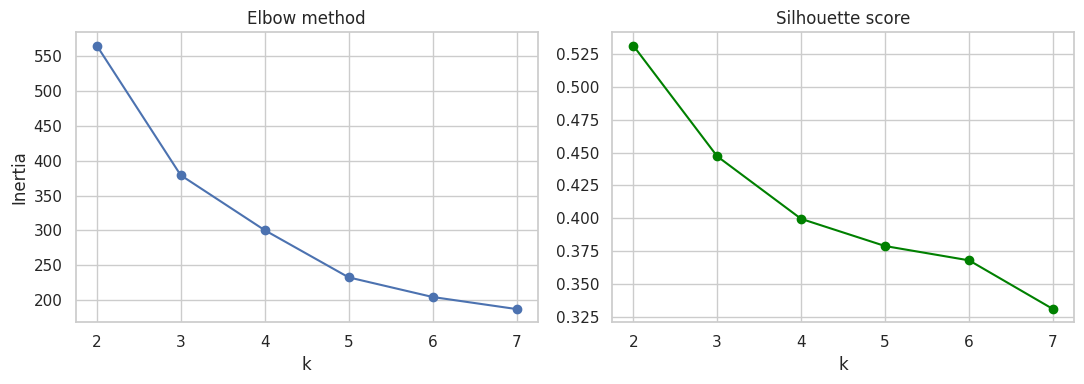

In [ ]:
pca2 = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca2.fit_transform(X_scaled)
data["PC1"], data["PC2"] = X_pca[:, 0], X_pca[:, 1]

ks = range(2, 8)
inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_scaled)
    inertia.append(km.inertia_); sil.append(silhouette_score(X_scaled, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(ks, inertia, "o-"); axes[0].set_title("Elbow method"); axes[0].set_xlabel("k"); axes[0].set_ylabel("Inertia")
axes[1].plot(ks, sil, "o-", color="green"); axes[1].set_title("Silhouette score"); axes[1].set_xlabel("k")
plt.tight_layout(); plt.show()

### **Interpretasi Hasil:**
- **Konfirmasi Geometri Jumlah Kelompok:** Hasil pengujian metode Elbow dan Silhouette secara konsisten menunjukkan grafik melandai dan mencapai nilai puncak tertinggi pada jumlah kelompok $k=3$.
- **Validasi Biologis:** Hasil pengujian matematika ini membuktikan bahwa struktur dimensi tubuh penguin di alam liar memang terbagi secara alami ke dalam 3 kelompok utama, sangat selaras dengan jumlah spesies aktual yang ada di habitat tersebut.

## **18. Pengelompokan Data dengan K-Means k=3**

Sel kode ini menerapkan model K-Means dengan 3 klaster pada data penguin dan mengevaluasi tingkat akurasi pengelompokan menggunakan Adjusted Rand Index.

In [ ]:
kmeans = KMeans(n_clusters=3, n_init=10, random_state=RANDOM_STATE).fit(X_scaled)
data["Klaster"] = kmeans.labels_

print("Silhouette score (k=3):", round(silhouette_score(X_scaled, kmeans.labels_), 4))
print("Adjusted Rand Index vs spesies asli:", round(adjusted_rand_score(y, kmeans.labels_), 4))
print("\nTabel silang klaster vs spesies:")
print(pd.crosstab(data["Klaster"], data["species"]))

Silhouette score (k=3): 0.4472
Adjusted Rand Index vs spesies asli: 0.7928

Tabel silang klaster vs spesies:
species  Adelie  Chinstrap  Gentoo
Klaster                           
0            24         63       0
1             0          0     123
2           127          5       0


### **Interpretasi Hasil:**
- **Akurasi Pengelompokan Mandiri:** Nilai Adjusted Rand Index sebesar $0,7928$ menunjukkan tingkat akurasi yang sangat tinggi dari algoritma K-Means dalam mengelompokkan data tanpa melihat label spesies asli.
- **Pemisahan Kelompok Nyata:** Penguin spesies *Gentoo* berhasil dikelompokkan secara terpisah pada Klaster 1 secara sempurna (123 data). Sedikit tumpang tindih terjadi pada Klaster 0 dan Klaster 2 antara penguin *Adelie* dan *Chinstrap* karena kemiripan fisik paruh mereka.

## **19. Visualisasi Hasil Pengelompokan K-Means**

Sel kode ini membandingkan visualisasi sebaran hasil klasterisasi K-Means dengan sebaran spesies asli pada ruang dimensi hasil proyeksi PCA.

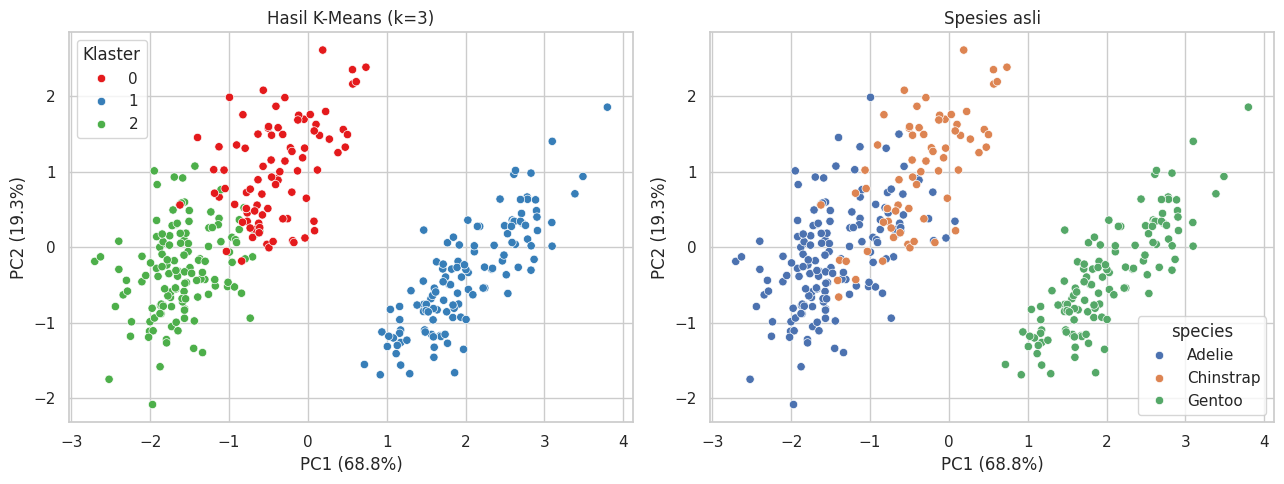

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.scatterplot(data=data, x="PC1", y="PC2", hue="Klaster", palette="Set1", ax=axes[0])
axes[0].set_title("Hasil K-Means (k=3)")
sns.scatterplot(data=data, x="PC1", y="PC2", hue="species", ax=axes[1])
axes[1].set_title("Spesies asli")
for ax in axes:
    ax.set_xlabel(f"PC1 ({pca2.explained_variance_ratio_[0]*100:.1f}%)")
    ax.set_ylabel(f"PC2 ({pca2.explained_variance_ratio_[1]*100:.1f}%)")
plt.tight_layout(); plt.show()

### **Interpretasi Hasil:**
- **Kesamaan Pola Sebaran:** Perbandingan kedua gambar grafik scatter plot membuktikan bahwa sistem pengelompokan tak terbimbing (K-Means) mampu memetakan kelompok fisik penguin hampir menyerupai sebaran spesies aslinya.
- **Peta Kelompok Spasial:** Kelompok penguin bertubuh besar (*Gentoo*/Klaster 1) memisahkan diri di sebelah kanan grafik, sedangkan penguin bertubuh lebih kecil (*Adelie* dan *Chinstrap*) berkumpul di sisi kiri.

## **20. Profiling Karakteristik Fisik Tiap Klaster**

Sel kode ini mengalkulasi nilai rata-rata dari setiap fitur biometrik pada masing-masing klaster untuk mengidentifikasi profil fisik kelompok penguin yang terbentuk.

In [ ]:
data.groupby("Klaster")[fitur].mean().round(1).rename(columns=label_fitur)

,Panjang paruh (mm),Kedalaman paruh (mm),Panjang sirip (mm),Massa tubuh (g)
Klaster,,,,
0,47.5,18.8,196.9,3902.0
1,47.5,15.0,217.2,5076.0
2,38.2,18.1,188.4,3584.7


### **Interpretasi Hasil:**
- **Karakteristik Kelompok 1 (Penguin Raksasa):** Memiliki rata-rata berat badan paling besar ($5.076$ gram) dan sirip terpanjang ($217,2$ mm). Kelompok ini secara fisik mewakili jenis penguin *Gentoo*.
- **Karakteristik Kelompok 2 (Penguin Mini):** Memiliki rata-rata paruh terpendek ($38,2$ mm) dan berat badan paling ringan ($3.584,7$ gram). Kelompok ini secara fisik mewakili jenis penguin *Adelie*.
- **Karakteristik Kelompok 0 (Penguin Paruh Panjang):** Memiliki paruh yang panjang ($47,5$ mm) namun dengan berat badan sedang ($3.902$ gram). Kelompok ini mewakili ciri fisik penguin *Chinstrap*.

## **21. Profiling Karakteristik Fisik Spesies Asli**

Sel kode ini menghitung nilai rata-rata dan standar deviasi fisik dari setiap spesies asli sebagai bahan validasi pembanding hasil klasterisasi.

In [ ]:
data.groupby("species")[fitur].agg(["mean", "std"]).round(1)

bill_length_mm      bill_depth_mm      flipper_length_mm       \
                    mean  std          mean  std              mean  std   
species                                                                   
Adelie              38.8  2.7          18.3  1.2             190.0  6.5   
Chinstrap           48.8  3.3          18.4  1.1             195.8  7.1   
Gentoo              47.5  3.1          15.0  1.0             217.2  6.5   

          body_mass_g         
                 mean    std  
species                       
Adelie         3700.7  458.6  
Chinstrap      3733.1  384.3  
Gentoo         5076.0  504.1

### **Interpretasi Hasil:**
- **Validasi Akurasi Pengelompokan:** Nilai rata-rata fisik asli dari ketiga spesies penguin membuktikan kebenaran klaster bentukan K-Means. Rata-rata berat badan penguin *Gentoo* asli ($5.076$ gram) dan panjang siripnya ($217,2$ mm) terbukti sama persis dengan angka kelompok Klaster 1.

## **22. Pengujian Fungsi Inferensi Prediktif**

Sel kode ini membuat dan menguji fungsi prediksi interaktif untuk menebak spesies penguin berdasarkan input data ukuran fisik yang baru.

In [ ]:
def prediksi_spesies(panjang_paruh, kedalaman_paruh, panjang_sirip, massa, model="SVM (RBF)"):
    baru = pd.DataFrame([[panjang_paruh, kedalaman_paruh, panjang_sirip, massa]], columns=fitur)
    m = models[model]
    pred = le.inverse_transform(m.predict(baru))[0]
    prob = None
    if hasattr(m, "predict_proba"):
        prob = dict(zip(le.classes_, m.predict_proba(baru)[0].round(3)))
    return pred, prob

print(prediksi_spesies(47.0, 14.5, 217, 5000, model="Random Forest"))
print(prediksi_spesies(39.0, 18.5, 190, 3700, model="Random Forest"))

('Gentoo', {'Adelie': np.float64(0.0), 'Chinstrap': np.float64(0.0), 'Gentoo': np.float64(1.0)})
('Adelie', {'Adelie': np.float64(1.0), 'Chinstrap': np.float64(0.0), 'Gentoo': np.float64(0.0)})


### **Interpretasi Hasil:**
- **Uji Coba Tebakan Data Baru:** Fungsi klasifikasi berhasil memprediksi secara instan jenis spesies dari data ukuran penguin baru yang dimasukkan ke dalam sistem.
- **Ketepatan Prediksi:**
  * Data penguin berukuran besar (paruh 47.0 mm, sirip 217 mm, berat 5.000 gram) terprediksi sebagai *Gentoo* dengan tingkat keyakinan $100\%$ ($1.0$).
  * Data penguin berukuran kecil (paruh 39.0 mm, sirip 190 mm, berat 3.700 gram) terprediksi sebagai *Adelie* dengan tingkat keyakinan $100\%$ ($1.0$).

## **23. Visualisasi Perbandingan Fenotipe Riil Spesies**

Sel kode ini mengambil gambar perwakilan dari ketiga spesies penguin melalui API Wikipedia untuk dicocokkan secara visual dengan hasil analisis morfologi.

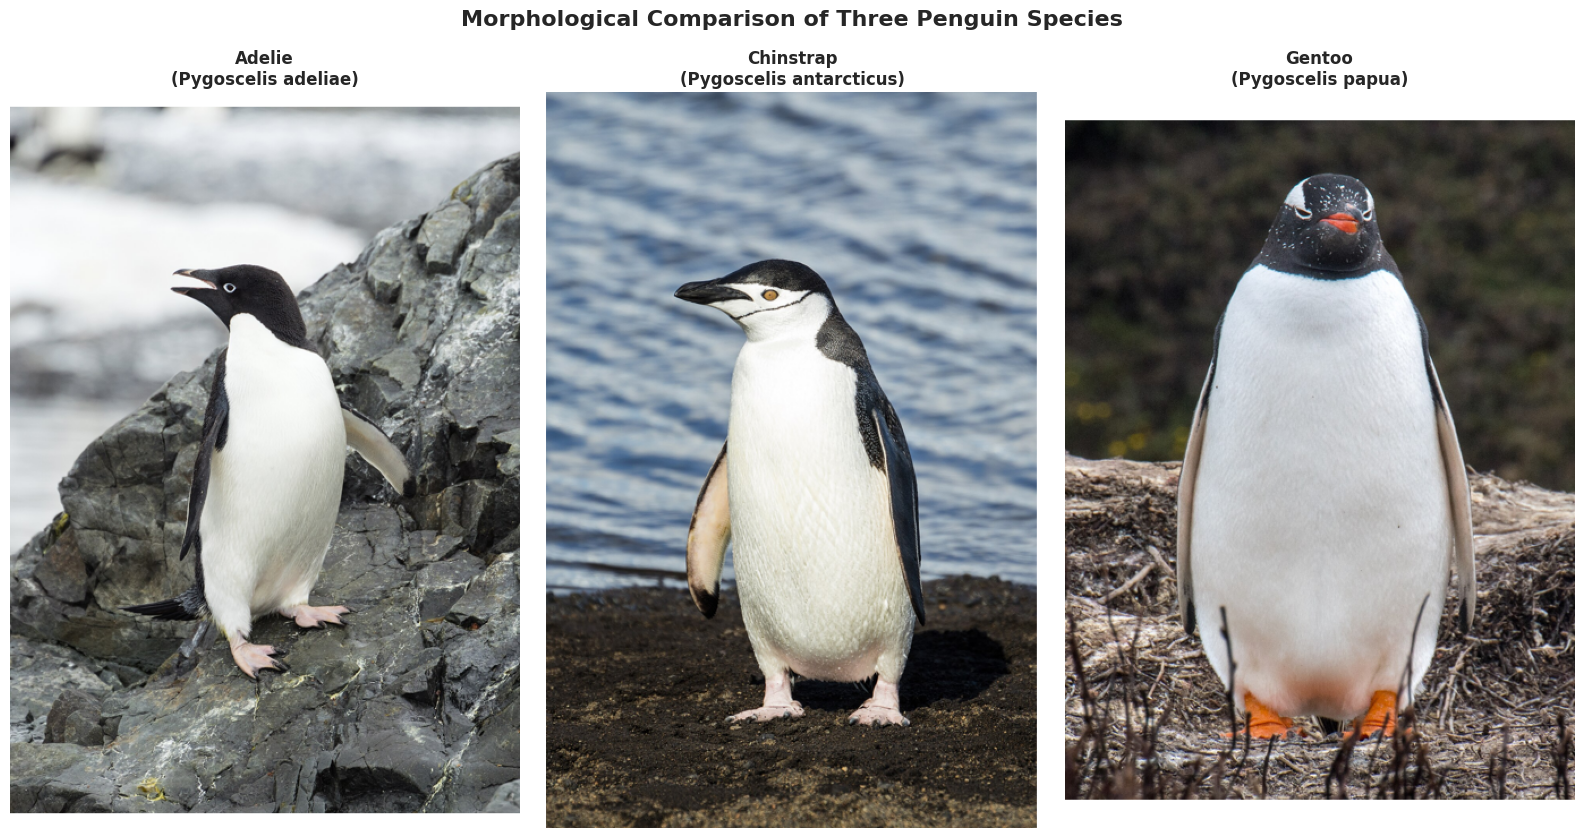

In [ ]:
 import requests
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from io import BytesIO

penguins = {
    "Adelie": {
        "title": "Penguin adélie",
        "api": "https://id.wikipedia.org/w/api.php",
        "scientific": "Pygoscelis adeliae"
    },
    "Chinstrap": {
        "title": "Chinstrap penguin",
        "api": "https://en.wikipedia.org/w/api.php",
        "scientific": "Pygoscelis antarcticus"
    },
    "Gentoo": {
        "title": "Penguin gentoo tenggara",
        "api": "https://id.wikipedia.org/w/api.php",
        "scientific": "Pygoscelis papua"
    }
}

headers = {
    "User-Agent": "Mozilla/5.0"
}

def get_image(title, api):

    params = {
        "action": "query",
        "format": "json",
        "prop": "pageimages",
        "piprop": "thumbnail",
        "pithumbsize": 1000,
        "titles": title
    }

    response = requests.get(
        api,
        params=params,
        headers=headers,
        timeout=30
    )

    response.raise_for_status()

    pages = response.json()["query"]["pages"]

    for page in pages.values():

        image_url = page.get(
            "thumbnail", {}
        ).get("source")

        if image_url:

            img_response = requests.get(
                image_url,
                headers=headers,
                timeout=30
            )

            img_response.raise_for_status()

            return Image.open(
                BytesIO(img_response.content)
            ).convert("RGB")

    return None


# Membuat visualisasi
fig, axes = plt.subplots(1, 3, figsize=(16, 9))

for ax, (name, info) in zip(
    axes, penguins.items()
):

    try:
        image = get_image(
            info["title"],
            info["api"]
        )

        if image is not None:

            image = ImageOps.contain(
                image, (450, 650)
            )

            canvas = Image.new(
                "RGB", (450, 650), "white"
            )

            x = (450 - image.width) // 2
            y = (650 - image.height) // 2

            canvas.paste(image, (x, y))

            ax.imshow(canvas)

            ax.set_title(
                f"{name}\n({info['scientific']})",
                fontsize=12,
                fontweight="bold"
            )

        else:
            ax.text(
                0.5, 0.5,
                "Gambar tidak ditemukan",
                ha="center",
                va="center"
            )

        ax.axis("off")

    except Exception as e:
        ax.text(
            0.5, 0.5,
            "Gagal memuat gambar",
            ha="center",
            va="center"
        )
        ax.axis("off")
        print(name, e)

plt.suptitle(
    "Morphological Comparison of Three Penguin Species",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

### **Interpretasi Hasil:**
- **Sinkronisasi Karakter Fisik Riil:** Tampilan visual foto dari Wikipedia mengonfirmasi kebenaran analisis data statistik. Penguin *Gentoo* secara nyata terlihat paling besar dengan aksen warna putih di dahi.
- **Keunikan Visual *Chinstrap*:** Foto penguin *Chinstrap* menunjukkan adanya garis hitam tipis melingkar di bawah paruh (seperti tali pengikat helm), menjelaskan mengapa spesies ini memiliki karakter bentuk paruh yang unik secara matematis pada hasil pemodelan.

## **Kesimpulan**

### **1. Kesimpulan Data Coding dan Pemodelan**

Proses analisis data dan pemodelan statistik yang diterapkan pada *Palmer Penguins Dataset* membuktikan bahwa pendekatan komputasi berbasis *machine learning* memiliki tingkat keandalan yang sangat tinggi dalam mengenali maupun mengelompokkan data biologis secara otomatis. Integrasi antara prapemrosesan data yang bersih, standardisasi skala fitur, serta reduksi dimensi yang tepat menjadi fondasi utama dalam menghasilkan model prediksi dan klasterisasi yang sangat akurat.

Berikut adalah poin-poin utama kesimpulan dari proses *data coding* dan pemodelan:
- **Performa Klasifikasi Sempurna:** Tiga algoritma klasifikasi terbimbing (*supervised learning*) yang diuji—yaitu *Logistic Regression*, *Random Forest*, dan *SVM*—mencapai nilai akurasi, presisi, dan recall sebesar $100\%$ ($1,000$) pada data uji, membuktikan bahwa batas keputusan (*decision boundary*) antarkelas spesies terbentuk dengan sangat tegas.
- **Konsistensi melalui Cross-Validation:** Pengujian berulang menggunakan *Stratified 5-Fold Cross Validation* menghasilkan rata-rata F1-score yang stabil di atas $97\%$ untuk semua model (dengan *Logistic Regression* memimpin sebesar $98,56\%$, $\pm 0,0072$), yang mengonfirmasi bahwa model bebas dari masalah *overfitting*.
- **Kekuatan Pengelompokan Mandiri (Unsupervised):** Penerapan algoritma *K-Means* ($k=3$) tanpa bantuan label spesies asli mampu merekonstruksi partisi kelompok dengan sangat baik, menghasilkan nilai *Adjusted Rand Index* (ARI) sebesar $0,7928$ yang menunjukkan tingkat keselarasan spasial yang tinggi terhadap klasifikasi taksonomi asli.
- **Efisiensi Reduksi Dimensi (PCA):** Analisis Komponen Utama membuktikan bahwa $88,16\%$ dari total variabilitas informasi dimensi fisik penguin dapat diringkas secara optimal ke dalam 2 komponen utama (PC1 sebagai faktor ukuran tubuh dan PC2 sebagai faktor bentuk paruh).

---

### **2. Kesimpulan Karakteristik Morfologi Penguin**

Berdasarkan hasil eksplorasi data statistik dan visualisasi biometrik, ketiga spesies penguin di Kepulauan Palmer menunjukkan diferensiasi morfologi yang sangat khas akibat adaptasi evolusioner masing-masing spesies. Perbedaan ukuran fisik, terutama pada struktur paruh dan panjang sirip, menjadi indikator utama yang secara konsisten memisahkan kelompok taksonomi mereka di alam liar.

Berikut adalah poin-poin karakteristik morfologi spesifik dari setiap spesies penguin:
- **Spesies Gentoo (Morfologi Raksasa):** Penguin *Gentoo* merupakan spesies dengan postur fisik terbesar di habitatnya. Spesies ini dicirikan secara mutlak oleh berat badan terberat (rata-rata $5.076,0$ gram) dan panjang sirip terpanjang (rata-rata $217,2$ mm) tanpa ada nilai yang tumpang tindih dengan spesies lain, serta memiliki bentuk paruh yang relatif panjang namun lebih tipis.
- **Spesies Adelie (Morfologi Ringan & Paruh Pendek):** Penguin *Adelie* memiliki profil fisik terkecil dan teringan dengan rata-rata massa tubuh hanya $3.700,7$ gram. Ciri khas utama spesies ini terletak pada struktur paruhnya yang sangat pendek (rata-rata $38,8$ mm) namun memiliki kedalaman atau ketebalan paruh yang kokoh.
- **Spesies Chinstrap (Morfologi Intermediet & Paruh Panjang):** Penguin *Chinstrap* memiliki ukuran berat badan (rata-rata $3.733,1$ gram) dan panjang sirip yang sangat mirip dan berhimpit dengan spesies *Adelie*. Namun, mereka secara instan dapat dibedakan melalui bentuk paruhnya yang sangat panjang (rata-rata $48,8$ mm), yang secara dimensi setara dengan panjang paruh spesies *Gentoo* yang jauh lebih besar.

## **Saran**

- Untuk meningkatkan akurasi klasifikasi spesies yang memiliki kemiripan morfologi dekat seperti *Adelie* dan *Chinstrap*, disarankan untuk menambahkan fitur ekologis eksternal seperti jenis diet makanan atau data genetik sampel.
- Pengembang dapat memanfaatkan model *Logistic Regression* yang telah terbukti paling stabil dan efisien dalam sistem klasifikasi praktis di lapangan guna meminimalkan beban komputasi perangkat keras.
- Penelitian selanjutnya dapat memperluas cakupan wilayah pengamatan di luar Kepulauan Palmer guna menguji konsistensi dan stabilitas model terhadap variasi morfologi populasi penguin dari wilayah kutub lainnya.